In [48]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [66]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
from collections import Counter
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from langdetect import detect, DetectorFactory

from src.features import limpiar_features_no_necesarias, multi_binarizer_format, multi_binarizer_genre, transformar_target_a_estrellas, es_parte_de_saga, normalize_format, extraer_generos_libro, detectar_language_code, one_hot_language, generar_embeddings_pca
from src.graficos import plot_boxplot_rating_por_genero, plot_generos_mas_frecuentes, plot_rating, plot_rating_por_genero, plot_stars, plot_boxplot_rating, plot_cantidad_generos_por_libro, plot_boxplot_rating_por_formato, plot_boxplot_rating_por_is_series, plot_scatte_rating_por_num_pages, plot_scatte_rating_por_publication_year, plot_boxplot_rating_por_autor_frecuent, plot_correlacion_features, plot_boxplot_rating_por_cant_generos
from src.utils import fusionar_libros

## 1. Comienzo por filtrar el dataset:

### 1.1 Primero saco las muestras de paises non-US:

In [3]:
# chunks = pd.read_json("goodreads_books.json", lines=True, chunksize=100_000)

# us_list = []
# for chunk in chunks:
#     us_list.append(chunk[chunk["country_code"] == "US"])

# df_us = pd.concat(us_list, ignore_index=True)
# print(df_us.shape)


### 1.2 Ahora me tengo que quedar nomas con los libros que son en ingles:

Consideramos los libros en ingles los que tienen "languade_code" = ["en", "eng", "en-US", "en-GB", "en-CA", "enm", "ang", "sco", "gem"]

Las ultimas 4 opciones son ingles, pero antiguos (afectara en el rating del libro?... Acaso como a las personas de hoy en dia les cosatara mas atenderlo y por eso le daran bajo rating?...)

Tambien me quedo con las muestras con ese valor NaN, porque aun no podemos decidir si descartarlos o no.

In [14]:
valid_langs = {"en", "eng", "en-us", "en-gb", "en-ca", "enm", "ang", "sco", "gem"}
# lang = df_us["language_code"].fillna("").str.strip().str.lower()
# df_us_eng = df_us[lang.isin(valid_langs) | (lang == "")]
# print(df_us_eng.shape)

Lo guardo en un json:

In [5]:
# import json
# output_path = "goodreads_us_english.json"
# chunk_size = 10000
# with open(output_path, "w", encoding="utf-8") as f:
#     for start in range(0, len(df_us_eng), chunk_size):
#         chunk = df_us_eng.iloc[start:start + chunk_size]
#         records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
#         for record in records:
#             json.dump(record, f, ensure_ascii=False)
#             f.write("\n")
# print("Guardado en", output_path)

Ahora abro el nuevo archivo que acabo de crear, asi trabajo sobre ese:

In [ ]:
chunks2 = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks2:
    chunk_list.append(chunk)

df_us_en = pd.concat(chunk_list, ignore_index=True)
print(df_us_en.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

(1925872, 29)


In [ ]:
#pd.set_option('display.max_columns', None)
#pd.set_option('display.width', None)
#
##otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
##tardo aprox 3min14s en correr
#K = 100_000
#sample = []
#
#with open("goodreads_us_english.json", encoding="utf8") as f:
#    for i, line in enumerate(f):
#        obj = json.loads(line)
#
#        if i < K:
#            sample.append(obj)
#        else:
#            j = random.randint(0, i)
#            if j < K:
#                sample[j] = obj
#
#df_us_en = pd.DataFrame(sample)
#
#print(df_us_en.shape)
#print(df_us_en.head())
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

(100000, 29)
         isbn text_reviews_count    series country_code language_code  \
0  0312853122                  1        []           US                 
1                             16        []           US                 
2  8476452063                  1  [758095]           US                 
3                             22  [842615]           US                 
4  9781911525                  2        []           US           eng   

                                     popular_shelves        asin is_ebook  \
0  [{'count': '3', 'name': 'to-read'}, {'count': ...                false   
1  [{'count': '1821', 'name': 'to-read'}, {'count...  B003F5NSVK     true   
2  [{'count': '55', 'name': 'to-read'}, {'count':...                false   
3  [{'count': '4091', 'name': 'to-read'}, {'count...  B01NAUWZ3X    false   
4      [{'count': '1', 'name': 'currently-reading'}]                false   

  average_rating kindle_asin  \
0           4.00               
1           3.83     

Primer filtrado:


Lo hacemos para reducir el tiempo de computo en las siguientes secciones.

Las decisiones fueron tomadas en base a analices que se hacen en secciones posteriores.

In [ ]:
# df_us_en = df_us_en[["text_reviews_count", "series", "language_code", "popular_shelves", "average_rating", "similar_books", "description", "format", "publication_year", "ratings_count", "title", "authors", "publisher", "num_pages"]]

In [ ]:
# df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors='coerce')
# df_us_en = df_us_en.dropna(subset=["average_rating"]) #Eliminamos todas las muetsras que tienen avergae_rating = NaN o = None
# df_us_en["estrellas"] = transformar_target_a_estrellas(df_us_en["average_rating"])
# if "format_group" not in df_us_en.columns:
#     df_us_en["format_group"] = df_us_en["format"].apply(normalize_format)
# df_us_en = df_us_en.drop(columns = ["format"]) 

# #is_series: feature binaria, true si es parte de una saga
# df_us_en["is_series"] = df_us_en["series"].apply(es_parte_de_saga)
# df_us_en = df_us_en.drop(columns = ["series"]) 

# df_us_en["publication_year"] = pd.to_numeric(df_us_en["publication_year"], errors='coerce')
# df_us_en["num_pages"] = pd.to_numeric(df_us_en["num_pages"],errors='coerce')

In [ ]:
#Las features "publication_year" y "num_pages" presetan valores NaN y algunos registros con valores extremos (ilogicos). 
#Como creemos que no hay una estrategia de imputacion que permita estimar esos valores de forma confiable y acorde a cada muestra en particular
#(la media o mediana no tendrian mucho sentido en estos casos), decidimos quedarnos solamente con las muestras que poseen años de publicacion 
#comprendidos entre 1440 (comienzo de la impresion) y 2026, y cantidad de paginas entre 1 y 10000. Este filtrado elimino simultaneamente aquellos 
#datos que poseian algun valor faltantes para alguna de estas dos caracterisitcas (este porcentaje de muestras es insignificante en comapracion
# a la cantidad total de datos que se posee).

# mask = df_us_en['publication_year'].between(1440, 2026) & df_us_en["num_pages"].between(1, 10000) #1440 es el año en que se invento la impresion
# df_us_en = df_us_en[mask]

In [ ]:
# import json
# output_path22 = "goodreads_us_english_primer_filtrado.json"
# chunk_size22 = 10000
# with open(output_path22, "w", encoding = "utf-8") as f:
#     for start in range(0, len(df_us_en), chunk_size22):
#         chunk = df_us_en.iloc[start:start + chunk_size22]
#         records = chunk.where(pd.notna(chunk), None).to_dict(orient = "records")
#         for record in records:
#             json.dump(record, f, ensure_ascii = False)
#             f.write("\n")
# print("Guardado en", output_path22)

Guardado en goodreads_us_english_primer_filtrado.json


Abro el nuevo json con este primer filtrado:

In [37]:
chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)

chunk_list33 = []
for chunk in chunks33:
    chunk_list33.append(chunk)

df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

(1146363, 15)


## 2. Reorganizo valores de features (breve inicio del preprocesamiento):

## 3. Analizo features (EDA):

### 3.1 Analisando el target

In [ ]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors='coerce') 
print(df_us_en["average_rating"].isna().sum())
print(df_us_en["average_rating"].max())
print(df_us_en["average_rating"].min())

0
5.0
0.0


En este sample, hay XX libros sin rating. Corresponde al XXX%. Podemos eliminar esos libros. Notamos aparte que no hay outliers. --> SIGUE EN PIE ESTO CON TODO EL DATASET???

In [9]:
#ELIMINAR EL TARGET CON NAN
df_us_en = df_us_en.dropna(subset=["average_rating"]) #Eliminamos todas las muetsras que tienen avergae_rating = NaN o = None
target_regresion = df_us_en["average_rating"]
df_us_en["estrellas"] = transformar_target_a_estrellas(target_regresion)

In [10]:
df_us_en["average_rating"].describe()

count    100000.000000
mean          3.882281
std           0.528781
min           0.000000
25%           3.640000
50%           3.920000
75%           4.170000
max           5.000000
Name: average_rating, dtype: float64

Como lo van a confirmar los graficos mas adelante, la mayoria de ratings se encuentran entre 3.5 y 4.5. 

In [11]:
df_us_en["estrellas"].value_counts(normalize=True).sort_index()

estrellas
0    0.00277
1    0.00199
2    0.01107
3    0.14408
4    0.76518
5    0.07491
Name: proportion, dtype: float64

El desbalanceo de clases se hace aun mas presente en el target para clasificacion.

In [12]:
target_clasificacion_balanceado = pd.qcut(df_us_en["average_rating"], q=5)
print(target_clasificacion_balanceado.value_counts().sort_index())

average_rating
(-0.001, 3.56]    20139
(3.56, 3.82]      20523
(3.82, 4.0]       20551
(4.0, 4.24]       19008
(4.24, 5.0]       19779
Name: count, dtype: int64


Esta estrategia permitiria mantener 5 clases balanceadas, pero perdemos la interpretabilidad de las 5 estrellas. 

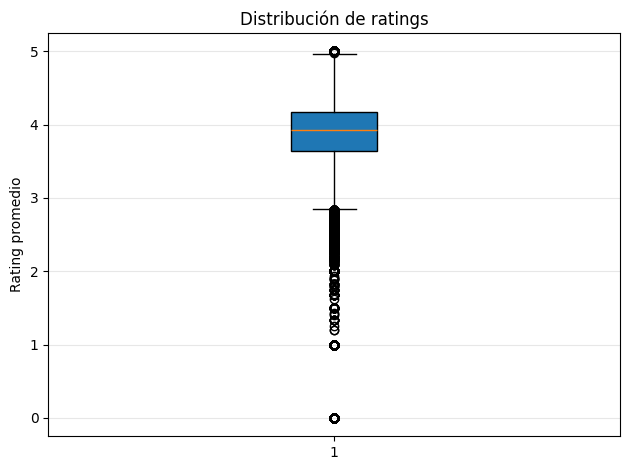

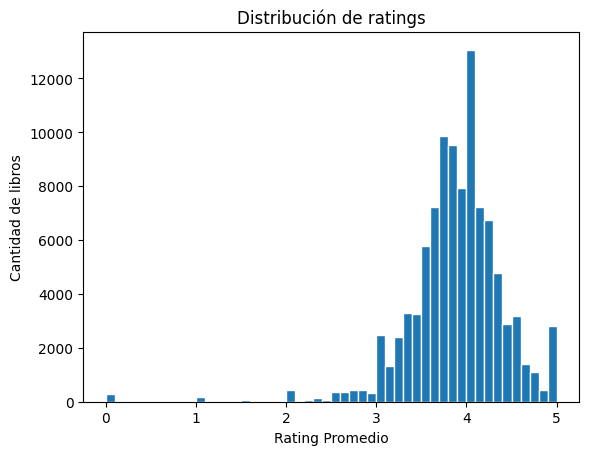

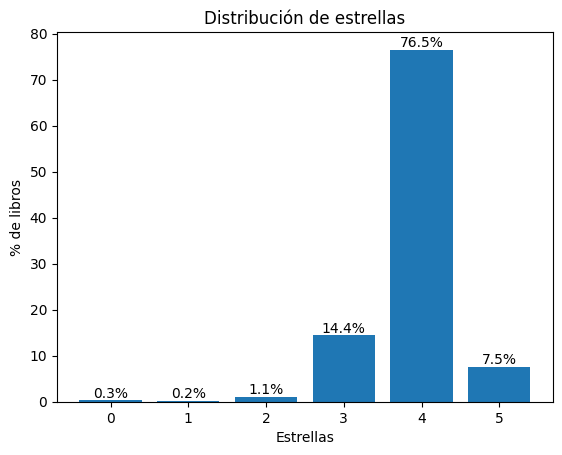

In [13]:
plot_boxplot_rating(df_us_en)
plot_rating(df_us_en)
plot_stars(df_us_en)

La mayoria de los ratings se encuentra entre 3.5 y 4.5. Este desbalance se hace mas presente al pasar el rating a estrellas. 

In [34]:
missing_summary = pd.DataFrame({
    "missing_count": df_us_en.isna().sum(),
    "missing_pct": df_us_en.isna().mean() * 100,
    "empty_string_count": (df_us_en == "").sum()
})
print(missing_summary)

NameError: name 'df_us_en' is not defined

### 3.2 Veo cuantas muestras tienen el laguage_code incompleto:

In [14]:
missing = df_us_en["language_code"].isna().sum() #Aplica para NaN y None
empty_str = (df_us_en["language_code"] == "").sum()
print("NaN:", missing)
print("Cadena vacía:", empty_str)
print("Total vacío:", missing + empty_str)

NaN: 0
Cadena vacía: 54967
Total vacío: 54967


Tiene sentido que hayan 0 NaN, porque cuando adquirimos las muestras para armar el dataset actual, convertimos los NaN en stirngs vacios (para veitar warnings)

### 3.3 ¿El formato del libro tiene alguna relacion con el rating?

En primer lugar, tenemos que agrupar las diferentes redacciones de cada formato:

In [15]:
# format_uniques = df_us_en["format"].unique()
# for v in format_uniques:
#     print(v)

In [16]:
# df_us_en["format"].value_counts().head(50)

In [ ]:
mixed = df_us_en["format"].str.contains("paperback.*ebook|ebook.*paperback|kindle.*paperback|paperback.*kindle", case=False, na=False)
print(mixed.sum())

8


In [18]:
#Le aplico la funcion para reagrupar:
if "format_group" not in df_us_en.columns:
    df_us_en["format_group"] = df_us_en["format"].apply(normalize_format)

print(df_us_en["format_group"].value_counts())

format_group
PAPERBACK    35695
UNKNOWN      30614
EBOOK        15250
HARDCOVER    14483
AUDIO         3519
OTHER          392
COMIC           47
Name: count, dtype: int64


In [19]:
df_us_en["format_group"].value_counts(normalize=True) * 100

format_group
PAPERBACK    35.695
UNKNOWN      30.614
EBOOK        15.250
HARDCOVER    14.483
AUDIO         3.519
OTHER         0.392
COMIC         0.047
Name: proportion, dtype: float64

Mas o menos el 99.59% de las muestars quedaron clasificadas en categorias concretas --> esto esta muy bueno!
Y podemos ver que hay muhcos UNKOWNS, lo que signfica que el usuario no compleot la info

In [20]:
#df_us_en.groupby("format_group").apply(lambda x: pd.to_numeric(x["average_rating"], errors="coerce").mean())

In [21]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors="coerce")
df_us_en.groupby("format_group")["average_rating"].agg(["count", "mean", "std"])

,count,mean,std
format_group,,,
AUDIO,3519,3.897477,0.320436
COMIC,47,3.962766,0.374350
EBOOK,15250,3.903898,0.519678
HARDCOVER,14483,3.840075,0.515275
OTHER,392,3.868036,0.625059
PAPERBACK,35695,3.880505,0.510513
UNKNOWN,30614,3.891864,0.575447


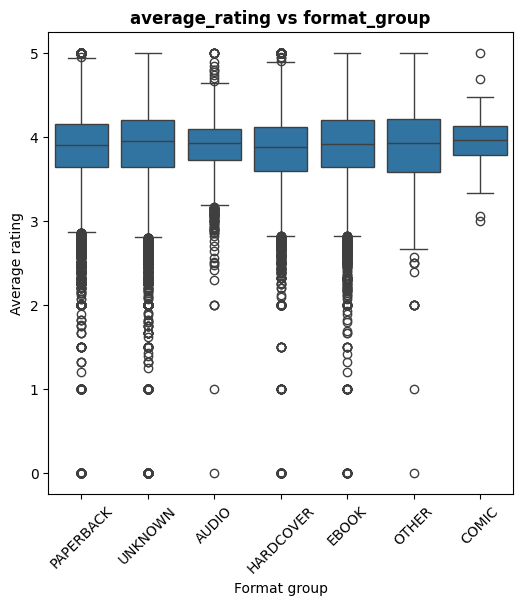

In [22]:
plot_boxplot_rating_por_formato(df_us_en)

Visualmente todas las lineas (meidanas) quedaron casi a la misma altura. Esto sugiere que Ee rating tipico de los libros es muy parecido independientemente del formato. 

Y como las cajas tienen tamaños similares, eso indica que la dispersion de los ratings tambien es parecida.

Ahora, como la cantidad de muestras por categoria es muy significativa, tambien hay que analizar los valores estadisitcos (de la tabla de arriba):

En cuanto al mean --> La diferencia entre el mas alto y el mas bajo es: 3.910 - 3.837 = 0.073. Entonces, si bien existen pequeñas diferencias entre categorias, los valores medios de average_rating son muy similares para todos los formatos que estamos analizando. Esto sugiere que el formato de publicacion no presenta una relacion fuerte con la valoracion promedio de los libros.

En cuanto al std --> Los audiolibros tienen una dispersion bastante menor. Esto podria indicar que los audiolibros suelen recibir ratings mas consistentes, o que hay menos titulos de muy baja valoración dentro de AUDIO.

### 3.4 La variable is_ebook, es util teniendo en cuenta que vamos a hacer un one hot encoding a la nueva feature de format_group?

### 3.5 "series"

In [23]:
df_us_en["series"].str.len().value_counts().sort_index()

series
0    67945
1    29405
2     2132
3      363
4      155
Name: count, dtype: int64

La feature "series" contiene una lista. Si la lista esta vacia el libro no es parte de una saga. No tiene valores Nan o que no sean una lista. --> esto ultimo se mantiene con este nuevo dataset???

In [24]:
#is_series: feature binaria, true si es parte de una saga
df_us_en["is_series"] = df_us_en["series"].apply(es_parte_de_saga)
df_us_en = df_us_en.drop(columns = ["series"]) 

Creamos la feature is_series, que tiene "true" si el libro es parte de una saga (es decir el largo de la lista de la feature "series" es mayor a 0), "false" sino.

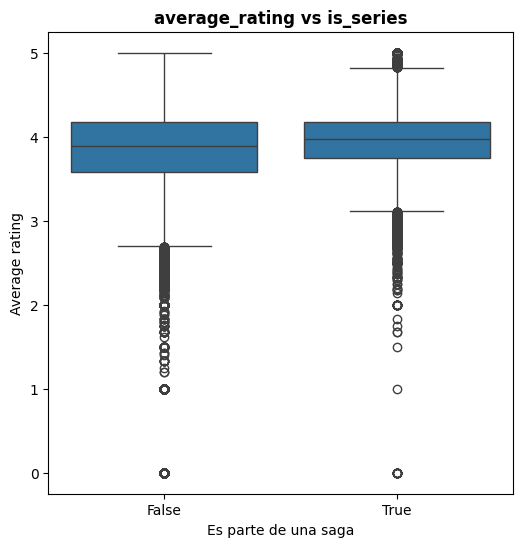

In [25]:
plot_boxplot_rating_por_is_series(df_us_en)

Los libros que pertenecen a una saga tienen ratings ligeramente mas altos --> La mediana de is_series = True esta un poco por encima de la de is_series = False

In [26]:
df_us_en.groupby("is_series")["average_rating"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
is_series,,,,
False,67945,3.849538,3.89,0.589220
True,32055,3.951686,3.97,0.359583


La diferencia de medias es: 3.953 - 3.853 = 0.100, y la diferencia de medianas es: 3.97 - 3.89 = 0.08

Esto puede parecer poco, pero, como ya vimos antes, en Goodreads los ratings suelen concentrarse mucho entre 3.5 y 4.5.

Es por esto que, una diferencia de 0.10 puntos en un dataset de casi 2 millones de observaciones no es despreciable.

Ademas, la dispersión cambia bastante: std(False) = 0.591 y std(True)  = 0.359. --> Los libros que pertenecen a sagas tienen ratings mucho mas concentrados. Visualmente, esto tambien se veia en el boxplot: la caja de True es mas compacta; hay menos valores extremadamente bajos; los ratings estaban mas agrupados alrededor de 4. 

Posible explicacion --> Sesgo de supervivencia: Muchas sagas continuan publicandose porque: los primeros libros tuvieron exito; los lectores siguieron comprando; la comunidad de fans se consolido. Por lo tanto, los libros de sagas suelen partir de una base de lectores mas favorable.

### 3.6 "publication_year" y "num_pages"

In [ ]:
df_us_en[["publication_year","num_pages"]].describe()
df_us_en["publication_year"] = pd.to_numeric(df_us_en["publication_year"], errors='coerce')
df_us_en["num_pages"] = pd.to_numeric(df_us_en["num_pages"],errors='coerce')
df_us_en[["publication_year","num_pages"]].describe()
print(df_us_en["num_pages"].isna().sum())
print(df_us_en["publication_year"].isna().sum())

36754
28414


Noto que hay que tratar con varios nan en publication year y num pages. Hay que decidir como tratar eso.

##### Analizando "num_pages"

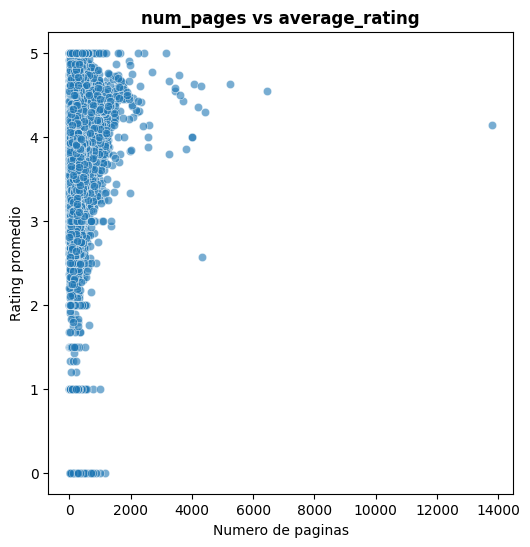

In [28]:
plot_scatte_rating_por_num_pages(df_us_en)

Definitvamente hay outliers -> consideramos que habria que eliminar los puntos que superan una cantidad ridicula de paginas

Vemos que para una misma aprox cantidad de hojas el rating varia muchismo (adopta casi todo los valores posibles) --> no sera una feature que por si sola determine mucho el target

Quiero cheqeuar el min y max de cantidad de hojas (porque no tendria sentido, por ejemplo, un libro con 0 hojas...)

In [29]:
print(df_us_en["num_pages"].max())
print(df_us_en["num_pages"].min())

13800.0
0.0


Definitivamente vamos a tener que eliminar outliers y valores ilogicos... 

##### Analizando "publication_year"

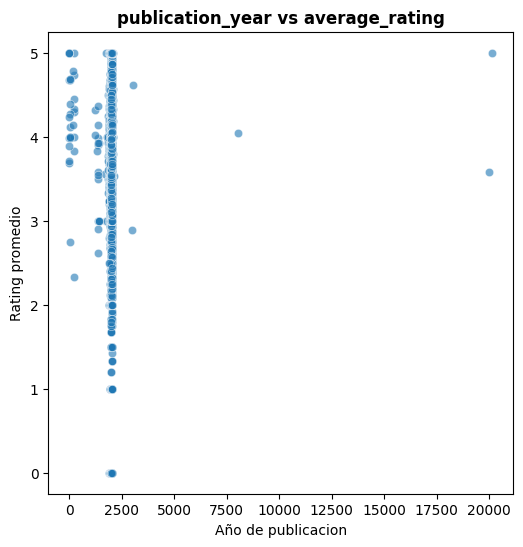

In [30]:
plot_scatte_rating_por_publication_year(df_us_en)

Al igual que con "num_pages", a esta escala, pareceria que la feature no es muy relevante para el target. Y posee MUCHOS mas outliers que "num_pages". Mas bien, son valores mal cargados, porque no tiene sentido que el año de publicacion sea mas grande que 2026...

Veamos en un escala mas chica (rango de años mas razonable):

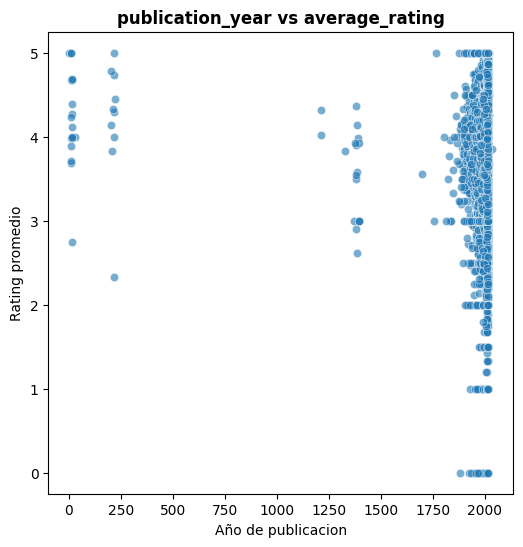

In [31]:
df_filtrado_publi_year = df_us_en[df_us_en["publication_year"] <= 2040]
plot_scatte_rating_por_publication_year(df_filtrado_publi_year)

Definitivamente a simple vista no se puede identificar una fuerte realcion entre el targte y esta variable, pero seguimos descubirendo posible outliers... --> Como son los titulos de tiene año de publicacion cerca de cero? Porque si son antiguos tendria sentido, pero sino, son datos mal registrados...

### 3.7 Buscando la feature "genero"

In [32]:
for i in range(5): #imprimo algunos ejemplos de las bibliotecas mas elegidas para guardar el libro
    print(f"Libro {i}")
    print(df_us_en["popular_shelves"].iloc[i])
    print()

Libro 0
[{'count': '3', 'name': 'to-read'}, {'count': '1', 'name': 'p'}, {'count': '1', 'name': 'collection'}, {'count': '1', 'name': 'w-c-fields'}, {'count': '1', 'name': 'biography'}]

Libro 1
[{'count': '1821', 'name': 'to-read'}, {'count': '192', 'name': 'non-fiction'}, {'count': '165', 'name': 'science'}, {'count': '128', 'name': 'currently-reading'}, {'count': '114', 'name': 'history'}, {'count': '91', 'name': 'anthropology'}, {'count': '75', 'name': 'nonfiction'}, {'count': '42', 'name': 'food'}, {'count': '40', 'name': 'evolution'}, {'count': '24', 'name': 'biology'}, {'count': '20', 'name': 'cooking'}, {'count': '18', 'name': 'favorites'}, {'count': '13', 'name': 'health'}, {'count': '12', 'name': 'nutrition'}, {'count': '12', 'name': 'library'}, {'count': '11', 'name': 'owned'}, {'count': '11', 'name': 'ebooks'}, {'count': '10', 'name': 'food-history'}, {'count': '9', 'name': 'audiobook'}, {'count': '9', 'name': 'social-science'}, {'count': '8', 'name': 'books-i-own'}, {'coun

In [ ]:
#imprimo las estanterias mas populares
chunks = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)
contador = Counter()
for chunk in tqdm(chunks):
    for shelves in chunk["popular_shelves"]:
        for shelf in shelves:
            contador[shelf["name"]] += int(shelf["count"])
contador.most_common(2000)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

Varias de estas estanterias no son generos (ej: to-read). En base a estos ejemplos, creo una funcion que detecta diferentes maneras de llamar a un mismo genero. Por ejemplo, "young-adult" y "ya" corresponden al mismo genero. Aparte, si un libro tiene como genero "historical-fiction" se podria decir que tiene como generos "historical" y fiction". Filtro estos diccionarios para extraer una lista de generos para cada libro. 

In [34]:
df_us_en["genres"] = df_us_en["popular_shelves"].apply(extraer_generos_libro)
sin_genero = (df_us_en["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero/len(df_us_en):.2f}%")

Porcentaje de libros sin genero: 12.42%


Una vez aplicada esta funcion, noto que el 12% de los libros no tienen genero. Viendo algunos libros, noto que de base el diccionario no tenia generos, no es que la funcion no esta detectando correctamente variantes de generos. 

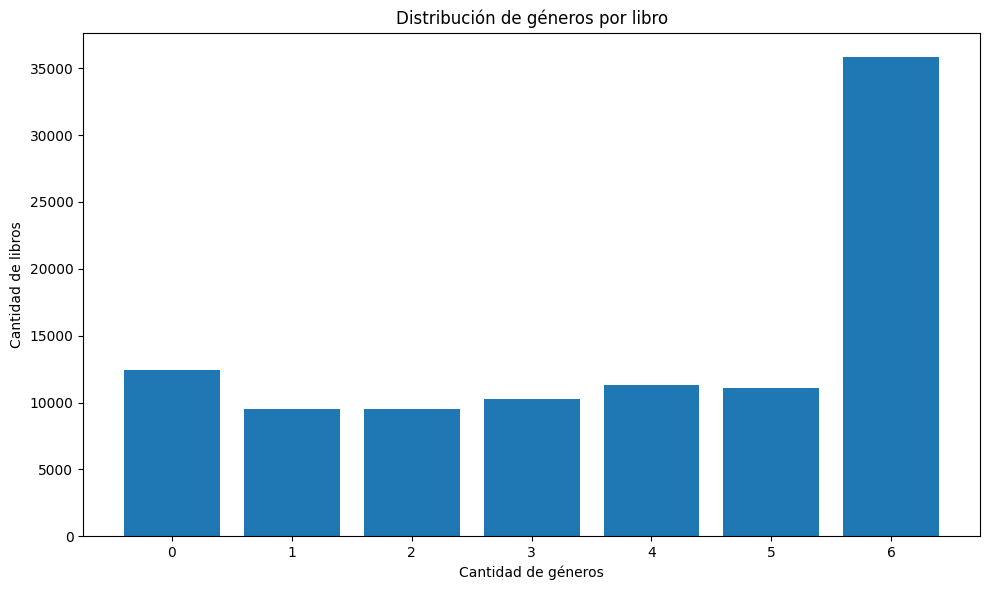

In [35]:
plot_cantidad_generos_por_libro(df_us_en)

En un primer momento, este grafico mostraba que habia libros con 18 generos. Varios de estos eran falsos positivos o ruido. Para evitar esto, elijo un maximo de 6 generos por libro.
Estas distribuciones resultan mucho mas razonables

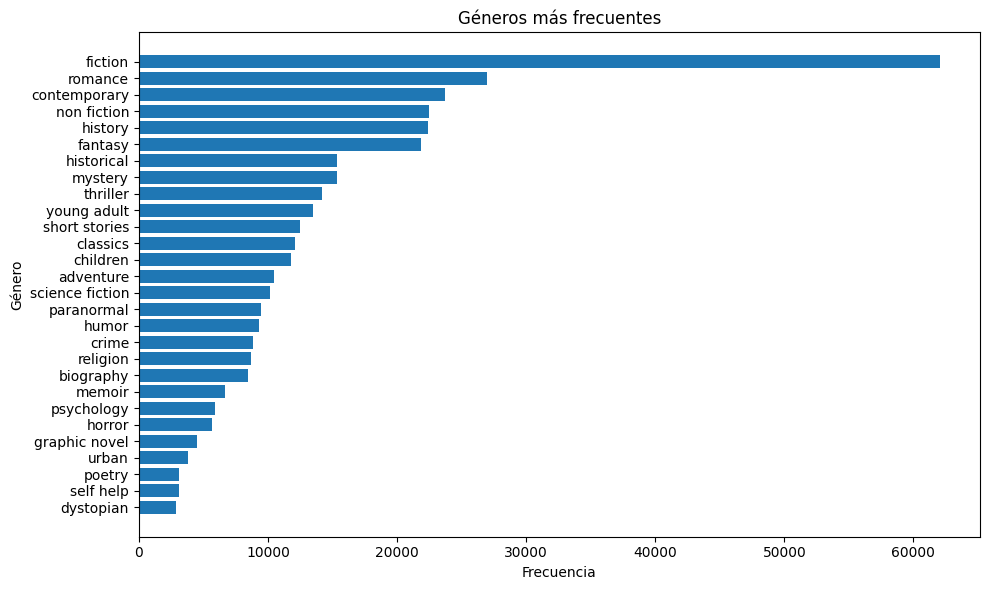

In [36]:
contador_generos = (df_us_en["genres"].explode().value_counts()) #.explode() separa los elementos de la lista
plot_generos_mas_frecuentes(contador_generos)

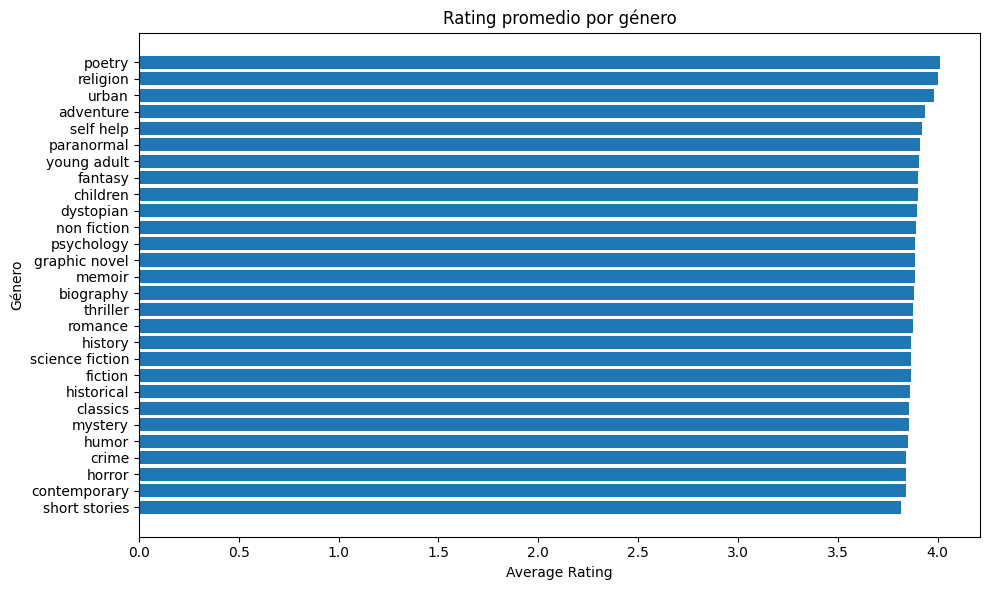

In [37]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"],errors="coerce")
plot_rating_por_genero(df_us_en)

Hay una leve diferencia entre el rating de los generos, pero esta permanece entre 3.7 y 4.

<Figure size 1200x600 with 0 Axes>

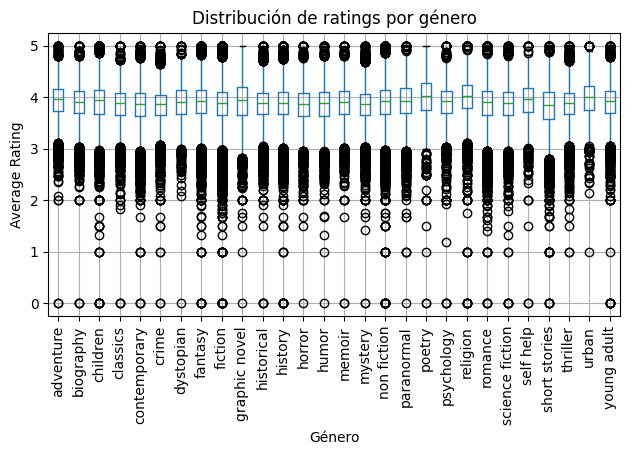

In [38]:
plot_boxplot_rating_por_genero(df_us_en)

### 3.8 "author"

In [39]:
# Tomo el primer autor de cada libro
df = df_us_en.copy()
df["author_id"] = df["authors"].apply(lambda x: x[0]["author_id"] if isinstance(x, list) and len(x) > 0 else None)

In [40]:
top_autores = df["author_id"].value_counts().head(10)
print(top_autores)

author_id
123715     125
3780       117
3389       103
5158478    103
625         94
947         87
239579      81
1265        71
2448        66
5481957     57
Name: count, dtype: int64


In [41]:
for autor_id in top_autores.index:
    print(f"\nAutor {autor_id}")
    print(df[df["author_id"] == autor_id]["title"].head(20).to_list())


Autor 123715
['The Moving Finger (Miss Marple, #4)', 'Death on the Nile (Hercule Poirot #17)', 'The Hollow (Hercule Poirot, #25)', 'Sparkling Cyanide (Colonel Race, #4)', 'Postern of Fate (Tommy and Tuppence #5)', 'Funerals Are Fatal', "Mrs. McGinty's Dead", 'By the Pricking of My Thumbs', 'The Secret Adversary', 'The Mysterious Affair at Styles', 'Evil Under the Sun (Hercule Poirot, #23)', 'A Pocket Full of Rye', 'Murder in Mesopotamia (Hercule Poirot, #14)', 'El misterio del tren azul', 'Murder in the Calais Coach', 'The Adventure of the Egyptian Tomb: A Short Story', 'مزحة الموت', 'Third Girl', 'They Do It With Mirrors (Miss Marple #6)', 'Lord Edgware Dies (Hercule Poirot, #9)']

Autor 3780
['Woman of God', 'The Shut-In', 'Now You See Her', '2nd Chance', 'The Dangerous Days of Daniel X', 'Woman of God', 'Gone', 'Private India (Private #8)', 'The Murder House', 'Killer Chef', 'Confessions: The Private School Murders - FREE PREVIEW (The First 15 Chapters)', 'The Witnesses', 'The Gift

In [ ]:
print("Filas totales:", len(df))
print("Duplicados por URL:")
print(df["url"].duplicated().sum())
print("Duplicados por título:")
print(df["title"].duplicated().sum())

Filas totales: 100000
Duplicados por URL:
0
Duplicados por título:
4794


In [43]:
duplicados = df[df["title"].duplicated(keep=False)]
cantidad_por_titulo = duplicados.groupby("title").size().sort_values(ascending=False)

print(cantidad_por_titulo.head(20))

title
Selected Poems                  19
Dracula                         19
Wuthering Heights               16
Pride and Prejudice             15
Emma                            14
Frankenstein                    14
The Picture of Dorian Gray      13
Jane Eyre                       11
Persuasion                      10
Little Women                    10
The Hobbit                      10
The Adventures of Tom Sawyer     9
Sense and Sensibility            9
The Time Machine                 8
Northanger Abbey                 8
Beowulf                          8
The Road                         8
Macbeth                          8
A Christmas Carol                8
Great Expectations               8
dtype: int64


Los duplicados pueden indicar diferentes ediciones de un mismo libro. Esto tiene sentido ya que los libros mencionados son muy conocidos, tiene sentido que hayan sido publicados multiples veces.

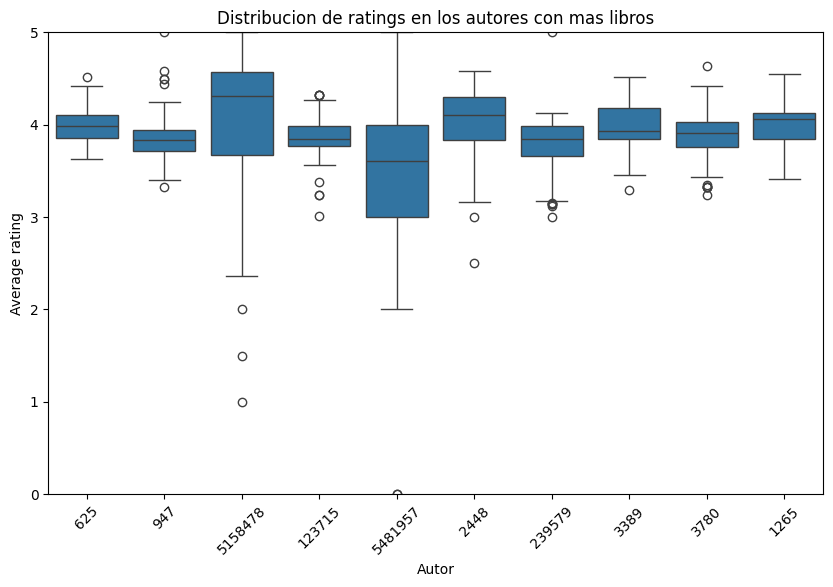

In [44]:
autores_top = top_autores.index
df_top = df[df["author_id"].isin(autores_top)]
plot_boxplot_rating_por_autor_frecuent(df_top, "Distribucion de ratings en los autores con mas libros")

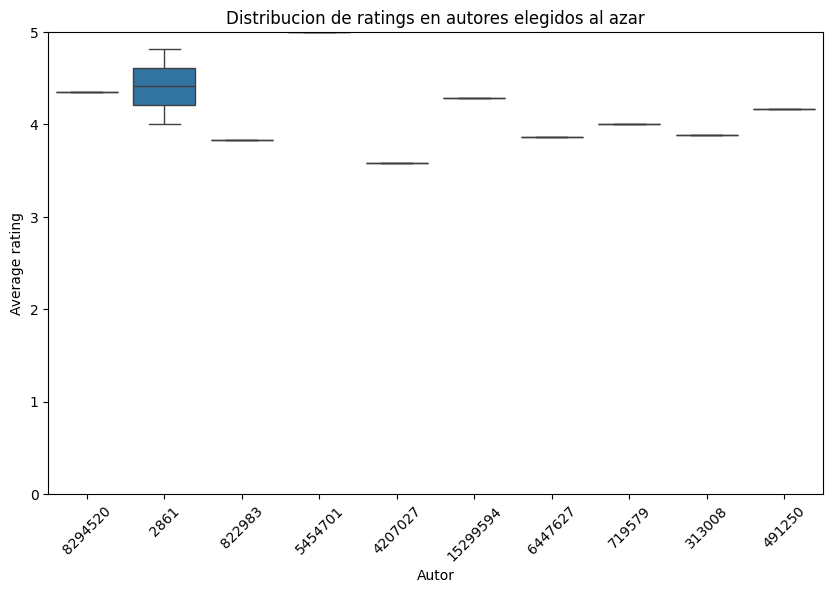

In [45]:
autores_random = df["author_id"].drop_duplicates().sample(10, random_state=42)
df_random = df[df["author_id"].isin(autores_random)]
plot_boxplot_rating_por_autor_frecuent(df_random, "Distribucion de ratings en autores elegidos al azar")

Cuando tomamos autores que no publicaron tantos libros observamos resultados mas dispersos.

### 3.9 Correlacion entre features

         isbn text_reviews_count country_code language_code  \
0  0312853122                  1           US                 
1                             16           US                 
2  8476452063                  1           US                 
3                             22           US                 
4  9781911525                  2           US           eng   

                                     popular_shelves        asin is_ebook  \
0  [{'count': '3', 'name': 'to-read'}, {'count': ...                false   
1  [{'count': '1821', 'name': 'to-read'}, {'count...  B003F5NSVK     true   
2  [{'count': '55', 'name': 'to-read'}, {'count':...                false   
3  [{'count': '4091', 'name': 'to-read'}, {'count...  B01NAUWZ3X    false   
4      [{'count': '1', 'name': 'currently-reading'}]                false   

   average_rating kindle_asin  \
0            4.00               
1            3.83               
2            4.54               
3            4.36         

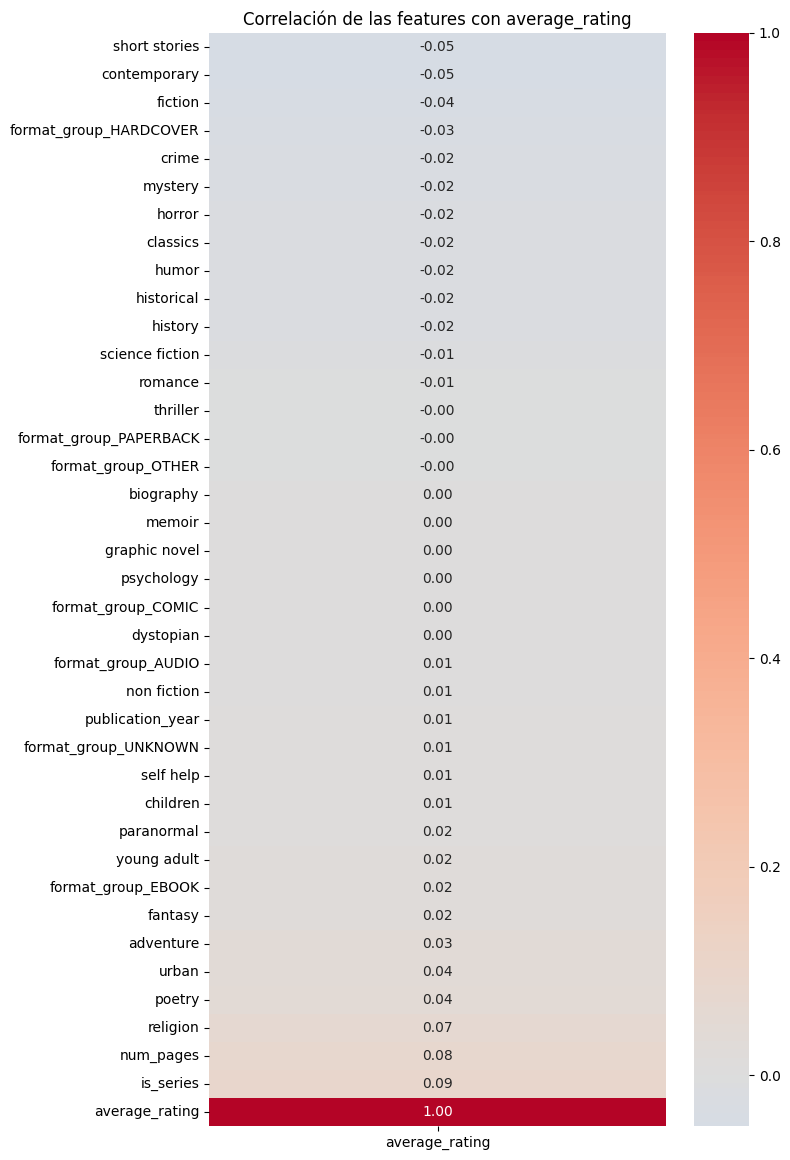

In [ ]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series","is_ebook","publication_year","num_pages","format_group_AUDIO","format_group_COMIC","format_group_EBOOK","format_group_HARDCOVER","format_group_OTHER","format_group_PAPERBACK","format_group_UNKNOWN",] + generos

#hago one hot de genero
df_us_en = one_hot_format(df_us_en) #one hot de format
df_us_en = multi_binarizer_genre(df_us_en) #multi binarizer de genero

#correlacion con el target
corr_rating = (df_us_en[features + ["average_rating"]].corr(numeric_only=True)["average_rating"].sort_values())
plot_correlacion_features(corr_rating)

Por si solas, estas features no aportan mucha informacion al modelo. Sin embargo, podemos intentar con algunas combinaciones:
- young adult * romance
- young adult * fantasy
- mystery * thriller
- len(generos)

### 3.10 "publisher"

Abro el archivo filtrado:

In [3]:
chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)

chunk_list33 = []
for chunk in chunks33:
    chunk_list33.append(chunk)

df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

(1146363, 15)


In [ ]:
top_publishers = df_us_en_1_filtro["publisher"].value_counts().head(10)
print(top_publishers)

publisher
                                               50545
Createspace Independent Publishing Platform    16171
Createspace                                     9347
Harlequin                                       8285
HarperCollins                                   7030
Penguin Books                                   6656
Oxford University Press, USA                    6320
Vintage                                         6061
Berkley                                         4833
Ballantine Books                                4802
Name: count, dtype: int64


In [5]:
publishers_unique = df_us_en_1_filtro["publisher"].unique()

In [7]:
print(len(publishers_unique))

114234


### 3.11 Valores NaN 

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df_us_en_1_filtro.isna().sum(),
    "missing_pct": df_us_en_1_filtro.isna().mean() * 100,
    "empty_string_count": (df_us_en_1_filtro == "").sum()
})
print(missing_summary)

                    missing_count  missing_pct  empty_string_count
text_reviews_count              0          0.0                   0
language_code                   0          0.0              586128
popular_shelves                 0          0.0                   0
average_rating                  0          0.0                   0
similar_books                   0          0.0                   0
description                     0          0.0               87649
publication_year                0          0.0                   0
ratings_count                   0          0.0                   0
title                           0          0.0                   4
authors                         0          0.0                   0
publisher                       0          0.0               50545
num_pages                       0          0.0                   0
estrellas                       0          0.0                   0
format_group                    0          0.0                

Analizamos los valores faltantes de la feature language_code:

In [ ]:
mask_lang = df_us_en_1_filtro["language_code"].fillna("").str.strip().eq("")
muestras_vacias_lang = df_us_en_1_filtro[mask_lang]
print(muestras_vacias_lang.shape)
display(muestras_vacias_lang.head(20))

(586128, 15)


,text_reviews_count,language_code,popular_shelves,average_rating,similar_books,description,publication_year,ratings_count,title,authors,publisher,num_pages,estrellas,format_group,is_series
0,1,,"[{'count': '3', 'name': 'to-read'}, {'count': ...",4.00,[],,1984,3,W.C. Fields: A Life on Film,"[{'author_id': '604031', 'role': ''}]",St. Martin's Press,256,4,PAPERBACK,False
3,7,,"[{'count': '56', 'name': 'to-read'}, {'count':...",4.13,[],"Relates in vigorous prose the tale of Aeneas, ...",2006,46,The Aeneid for Boys and Girls,"[{'author_id': '3041852', 'role': ''}]",Yesterday's Classics,162,4,PAPERBACK,False
4,6,,"[{'count': '515', 'name': 'to-read'}, {'count'...",4.22,"[948696, 439885, 274955, 12978730, 372986, 216...","To Kara's astonishment, she discovers that a p...",2009,98,All's Fairy in Love and War (Avalon: Web of Ma...,"[{'author_id': '19158', 'role': ''}]",Seven Seas,216,4,PAPERBACK,True
5,39,,"[{'count': '961', 'name': 'to-read'}, {'count'...",3.81,"[287151, 1104760, 1172822, 440292, 287082, 630...","Wisdom, humor, and dark observations by the fo...",2000,986,The Devil's Notebook,"[{'author_id': '2983296', 'role': ''}, {'autho...",Feral House,147,4,PAPERBACK,False
6,15,,"[{'count': '159', 'name': 'to-read'}, {'count'...",3.93,"[439108, 522621, 116770, 1275927, 6202655, 840...","London, 1196. At the command of Richard the Li...",2009,186,"Crowner Royal (Crowner John Mystery, #13)","[{'author_id': '37778', 'role': ''}]",Simon & Schuster UK,400,4,HARDCOVER,True
7,615,,"[{'count': '4248', 'name': 'to-read'}, {'count...",3.98,"[614054, 272343, 824934, 581383, 93598, 638689...",It's 1953 and 11-year-old Penny dreams of a su...,2006,6949,Penny from Heaven,"[{'author_id': '137561', 'role': ''}]",Random House Books for Young Readers,288,4,HARDCOVER,False
11,9,,"[{'count': '7615', 'name': 'to-read'}, {'count...",3.48,"[10596, 11532, 32453, 32430, 32640, 948244, 69...","Unabridged CDs, 25 CDs, 30 hours\nRead by TBA\...",2010,45,The Tommyknockers,"[{'author_id': '3389', 'role': ''}, {'author_i...",Penguin Audio,1,3,AUDIO,False
14,10,,"[{'count': '13', 'name': 'to-read'}, {'count':...",3.98,"[12505811, 12349615, 11890677, 13611511, 13112...",When single mother Danielle Jordan discovers h...,2011,71,Holding On,"[{'author_id': '5054653', 'role': ''}]",Createspace,290,4,PAPERBACK,False
17,17,,"[{'count': '429', 'name': 'classics'}, {'count...",3.57,"[1109271, 893023, 572268, 379255, 111723, 9904...","Hemingway's classic novel about contraband, in...",2006,45,To Have and Have Not,"[{'author_id': '1455', 'role': ''}, {'author_i...",Simon Schuster Audio,5,4,AUDIO,False
18,1,,"[{'count': '62', 'name': 'to-read'}, {'count':...",4.00,[],"WINNER, Business: Personal Finance/Investing, ...",2014,4,Investor Behavior: The Psychology of Financial...,"[{'author_id': '53167', 'role': ''}, {'author_...",Wiley,640,4,EBOOK,False


In [ ]:
#Para que los resultados sean reproducibles
DetectorFactory.seed = 42
# Tomamos una muestra
sample = (df_us_en_1_filtro[df_us_en_1_filtro["language_code"] == ""].sample(1000, random_state = 42).copy())
sample["detected_language"] = sample.apply(detectar_language_code, axis=1)
print(sample["detected_language"].value_counts(normalize=True).mul(100).round(2))

detected_language
en    96.3
es     0.9
fr     0.6
de     0.4
ar     0.3
cy     0.2
id     0.2
nl     0.2
sv     0.1
tl     0.1
sq     0.1
hr     0.1
no     0.1
vi     0.1
da     0.1
it     0.1
sl     0.1
Name: proportion, dtype: float64


In [38]:
df_us_en_1_filtro.loc[df_us_en_1_filtro["language_code"] == "", "detected_language"] = (df_us_en_1_filtro.loc[df_us_en_1_filtro["language_code"] == ""].apply(detect_book_language, axis=1))
print("Filas antes:", len(df_us_en_1_filtro))
# Conservamos las muestras con language_code original y != "", y filas con ese valor vacío, pero detectado como ingles:
df_us_en_1_filtro = df_us_en_1_filtro[(~(df_us_en_1_filtro["language_code"] == "")) | ((df_us_en_1_filtro["language_code"] == "") & (df_us_en_1_filtro["detected_language"] == "en"))]

# Completamos con "eng" los que fueron detectados como ingles:
df_us_en_1_filtro.loc[(df_us_en_1_filtro["language_code"] == "") &(df_us_en_1_filtro["detected_language"] == "en"), "language_code"] = "eng"

# Eliminamos la columna auxiliar creada:
df_us_en_1_filtro.drop(columns=["detected_language"], inplace=True )

print("Filas después:", len(df_us_en_1_filtro))
print(df_us_en_1_filtro["language_code"].value_counts())


Filas antes: 1146363
Filas después: 1117279
language_code
eng      1020325
en-US      58837
en-GB      36633
en-CA       1264
en           164
enm           35
ang           10
sco            9
gem            2
Name: count, dtype: int64


Analizo los valores faltantes de la feature "description": 

Como vamos a hacerles embeddings, puedo hacerle el embedding a un string vacio. Entonces, lo dejamos asi.

In [ ]:
(df_us_en_1_filtro["description"].fillna("").str.split().str.len().quantile([0.25, 0.5, 0.75, 0.9, 0.95])
)

0.25     67.0
0.50    123.0
0.75    179.0
0.90    242.0
0.95    290.0
Name: description, dtype: float64

En base a la longitud de los valores y al hecho de que esta tecnica es capaz de capturar el signficado del texto (coloca en el espacio vectorial a palabras con significados similares juntas), decidimos suar embeddings en vez de TF-IDF

Analizando los valores flatantes de "publisher":

In [25]:
df_us_en_1_filtro["publisher"].nunique()

107127

In [39]:
df_us_en_1_filtro["publisher"] = (df_us_en_1_filtro["publisher"].replace("", "UNKNOWN_PUBLISHER"))

## 4. Continuamos el preprocesamiento (se empezo un poco antes del EDA):

Comienzo por eliminar los outliers de "publication_year" y "number_pages":

In [ ]:
#Las features "publication_year" y "num_pages" presetan valores NaN y algunos registros con valores extremos (ilogicos). 
#Como creemos que no hay una estrategia de imputacion que permita estimar esos valores de forma confiable y acorde a cada muestra en particular
#(la media o mediana no tendrian mucho sentido en estos casos), decidimos quedarnos solamente con las muestras que poseen años de publicacion 
#comprendidos entre 1440 (comienzo de la impresion) y 2026, y cantidad de paginas entre 1 y 10000. Este filtrado elimino simultaneamente aquellos 
#datos que poseian algun valor faltant para alguna de estas dos caracterisitcas (este porcentaje de muestras es insignificante en comapracion
# a la cantidad total de datos que se posee).

# mask = df_us_en['publication_year'].between(1440, 2026) & df_us_en["num_pages"].between(1, 10000) #1440 es el año en que se invento la impresion
# df_us_en = df_us_en[mask].copy()
# #Guardar resultado
# df_us_en.to_json('goodreads_filtered.json', orient='records', lines=True)
# #O como CSV:
# df_us_en.to_csv('goodreads_filtered.csv', index=False)

In [ ]:
#df_procesado = transformar_features(df_us_en)
#df_entrenamiento = limpiar_features_no_necesarias(df)

KeyError: "['format_AUDIO', 'format_COMIC', 'format_EBOOK', 'format_HARDCOVER', 'format_OTHER', 'format_PAPERBACK', 'format_UNKNOWN'] not in index"

Ahora, tenemos que eliminar las observaciones poco confiables. Es decir, aquellas que poseen rating_count bajo (ya que indica que poseen un average_rating volatil):

In [30]:
bins_s4 = [0,1,2,5,10,20,50,100,500,np.inf]

df_us_en_1_filtro.groupby(pd.cut(df_us_en_1_filtro["ratings_count"], bins_s4))["average_rating"].agg(["count","mean","std"])

/var/folders/vz/dvp73rjn6bb_xqcp58j9_h900000gn/T/ipykernel_1216/2166363915.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_us_en_1_filtro.groupby(pd.cut(df_us_en_1_filtro["ratings_count"], bins_s4))["average_rating"].agg(["count","mean","std"])


,count,mean,std
ratings_count,,,
"(0.0, 1.0]",57911,3.899299,0.884761
"(1.0, 2.0]",47734,3.928565,0.707486
"(2.0, 5.0]",107666,3.926907,0.579613
"(5.0, 10.0]",120613,3.903313,0.484805
"(10.0, 20.0]",146259,3.876027,0.424697
"(20.0, 50.0]",202334,3.854788,0.375647
"(50.0, 100.0]",132203,3.848722,0.345317
"(100.0, 500.0]",190091,3.871453,0.317285
"(500.0, inf]",107055,3.937009,0.279153


Como sospechabamos, a medida que rating_count aumenta, disminuye el desvio estandar (la dispersion) del rating.

La caida mas fuerte ocurre en el rango de rating_count comenzando en (0.0, 1.0] hasta el de (5.0, 10.0]. Luego de ese rango, sigue bajando el std, pero mucho mas gradualmente. 

In [31]:
len(df_us_en_1_filtro)

1117279

In [32]:
len(df_us_en_1_filtro[df_us_en_1_filtro["ratings_count"] >= 10])

798118

Si hicieramos el corte en 10, perderiamos un 29% de mustras, aproximadamente (((1117279 - 798118) / 1117279) * 100).

In [33]:
len(df_us_en_1_filtro[df_us_en_1_filtro["ratings_count"] >= 20])

642982

En cambio, si hicieramos el corte en 20, perderiamos un 42% de mustras, aproximadamente (((1117279 - 642982) / 1117279) * 100).

Y si vemos la tabla de progreso de estabilidad, observamos que (10.0, 20.0] tiene un std ~ 0,42% y (20.0, 50.0] tiene un std ~ 0,37%. Es decir, que hay un 0,05% de mejora, lo cual no nos parece tan significante como para perder 155136 muestras adicionales (798118 - 642982).

In [40]:
df_us_en_1_filtro = df_us_en_1_filtro[df_us_en_1_filtro["ratings_count"] >= 10]

Aplicamos el filtro para la feature "genero":

In [41]:
df_us_en_1_filtro["genres"] = df_us_en_1_filtro["popular_shelves"].apply(extraer_generos_libro)
sin_genero_s4 = (df_us_en_1_filtro["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero_s4/len(df_us_en_1_filtro):.2f}%")

Porcentaje de libros sin genero: 1.80%


Como el porcentaje de muestras que poseen su feture genero vacia es muy bajo, podemos dejar el valor tal cual como esta ([]) (en vez de generar otra categoria artificial llamada, por ejemplo, "unknown") y usar nuestra MultiLabelBinarizer, la cual simplemente va a generar una lista de ceros.

Tambien queremos hacer generar una nueva feature llamada cantidad_generos, la cual indicara en cuantos generos se clasifico al libro (para ver si tiene alguna relaicon con el rating o no):

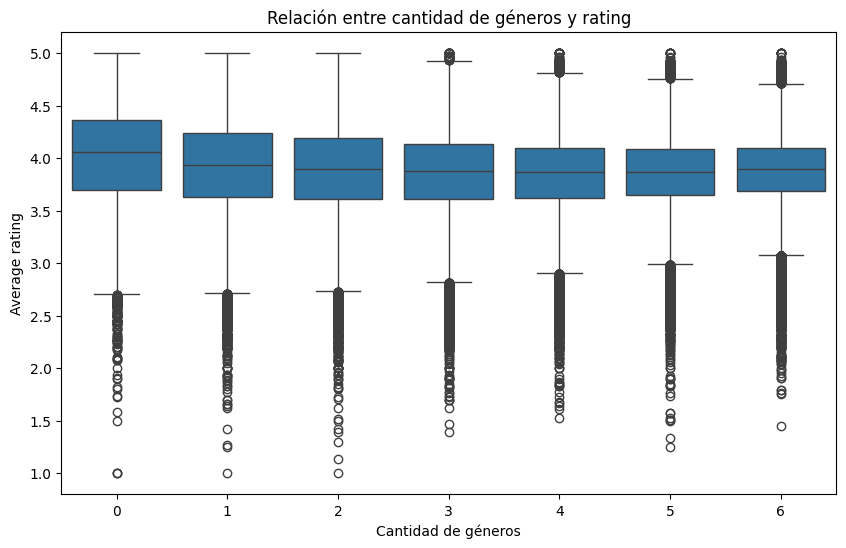

In [ ]:
df_us_en_1_filtro["cantidad_generos"] = df_us_en_1_filtro["genres"].apply(len)
plot_boxplot_rating_por_cant_generos(df_us_en_1_filtro)

Mirando el boxplot, no parece haber una relacion fuerte entre la cantidad de generos asignados a una muestra y su average_rating. Excepto por el caso en el que las muestras poseen la lista de generos vacias, el resto de las opciones parecen tener medianas muy parecidas. 

En conclusion, en base a este grafico, creemos que la cantidad de generos probablemnte tenga una correlacion muy baja con el rating, pero tal vez los generos especificos si aporten mas al target. 

Analisis pr aver si es necesario hacer split por autores:

In [60]:
# --- 1. Diagnóstico rápido: cuántos autores son "únicos" (1 solo libro) --- 
df_us_en_1_filtro["author_id"] = df_us_en_1_filtro["authors"].apply(lambda x: x[0]["author_id"] if isinstance(x, list) and len(x) > 0 else None)
autor_counts = df_us_en_1_filtro.groupby("author_id")["estrellas"].count()
print(f"Autores totales: {autor_counts.shape[0]}") 
print(f"Autores con 1 solo libro: {(autor_counts == 1).sum()} " f"({(autor_counts == 1).mean():.1%})") 
print(f"Autores con 2+ libros: {(autor_counts > 1).sum()} " f"({(autor_counts > 1).mean():.1%})") 
print(f"Libros que pertenecen a un autor con 2+ libros: {df_us_en_1_filtro['author_id'].map(autor_counts).gt(1).mean():.1%}")

Autores totales: 217236
Autores con 1 solo libro: 123911 (57.0%)
Autores con 2+ libros: 93325 (43.0%)
Libros que pertenecen a un autor con 2+ libros: 84.5%


Analizando la posible presencia de libros repetidos:

In [61]:
print(df_us_en_1_filtro["title"].duplicated().sum())
df_us_en_1_filtro["title"].value_counts().head(20)

183353


title
Selected Poems                      189
Pride and Prejudice                 161
Jane Eyre                           140
Wuthering Heights                   134
Dracula                             125
Frankenstein                        108
Emma                                105
The Great Gatsby                    103
The Picture of Dorian Gray           98
A Christmas Carol                    93
The Hobbit                           89
The Secret Garden                    86
Sense and Sensibility                86
Great Expectations                   79
Little Women                         78
Alice's Adventures in Wonderland     74
Treasure Island                      74
Northanger Abbey                     74
Persuasion                           73
Fahrenheit 451                       72
Name: count, dtype: int64

In [ ]:
df_us_en_1_filtro[df_us_en_1_filtro["title"] == "Pride and Prejudice"][["title", "authors", "publisher", "publcation_year", "num_pages", "format_group", "average_rating", "ratings_count"]].head(20)

,title,authors,publisher,publication_year,num_pages,format_group,average_rating,ratings_count
3883,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",YBM Si-sa,2006,239,PAPERBACK,4.25,710
7468,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Arcturus,2009,352,PAPERBACK,4.25,265
16146,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Sterling Publishing,2012,325,HARDCOVER,4.25,10
65890,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Signet Classic,1996,324,UNKNOWN,4.25,360
86825,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Sourcebooks,2010,258,EBOOK,4.25,41
99032,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Vintage,2007,368,PAPERBACK,4.25,476
100154,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",CreateSpace,2012,400,PAPERBACK,4.25,97
100864,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Worth Publishers,2007,348,HARDCOVER,4.25,52
101549,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Canterbury Classics,2012,315,OTHER,4.25,338
110222,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Recorded Books,1980,10,AUDIO,4.25,33


In [ ]:
def autor_principal(authors):
    try:
        return authors[0]["author_id"]
    except:
        return None

df_us_en_1_filtro["main_author"] = (df_us_en_1_filtro["authors"].apply(autor_principal))
duplicados = (df_us_en_1_filtro.groupby(["title", "main_author"]).size().sort_values(ascending=False))
duplicados.head(20)

title                             main_author
Pride and Prejudice               1265           157
Jane Eyre                         1036615        136
Wuthering Heights                 4191           130
Dracula                           6988           115
Frankenstein                      11139           99
The Great Gatsby                  3190            98
Emma                              1265            97
The Picture of Dorian Gray        3565            93
A Christmas Carol                 239579          88
The Hobbit                        656983          88
The Secret Garden                 2041            84
Sense and Sensibility             1265            82
Great Expectations                239579          73
Northanger Abbey                  1265            73
Persuasion                        1265            73
Fahrenheit 451                    1630            72
Little Women                      1315            70
Anna Karenina                     128382          70


Fusionamos los libros repetidos:

In [ ]:
#1. Tenemos que tener aseguro el autor para cada muestra (seccion 3.8)
#2. Escribimos el titulo en minusculas para que sean comparables entre muestras (por si es el mismo nombre, pero con algo diferente):
df_us_en_1_filtro["title_key"] = (df_us_en_1_filtro["title"].str.lower().str.strip())
df_us_en_1_filtro_fusionado = (df_us_en_1_filtro.groupby(["title_key", "author_id"], as_index = False).apply(fusionar_libros).reset_index(drop = True))

Transformamos las variables categoricas:

In [ ]:
#hago one hot de genero
df_us_en_1_filtro_fusionado = multi_binarizer_format(df_us_en_1_filtro_fusionado) #one hot de format
df_us_en_1_filtro_fusionado = multi_binarizer_genre(df_us_en_1_filtro_fusionado) #multi binarizer de genero

In [ ]:
df_us_en_1_filtro_fusionado = one_hot_language(df_us_en_1_filtro_fusionado) #one hot de language_code

## 5. Splitting:

In [ ]:
df_dev, df_test = train_test_split(df_us_en, test_size = 0.2, stratify = df_us_en["estrellas"], random_state = 42)
df_train, df_val = train_test_split(df_dev, test_size = 0.2, stratify = df_dev["estrellas"], random_state = 42)

#verifico tamanios de los dfs con respecto al original
#tome 80-20 para dev-test, y a dev lo separe con 80-20 en train y val
print(f"Train: {len(df_train)} ({len(df_train)/len(df_us_en):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df_us_en):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df_us_en):.1%})")

#verifico la distribucion de las estrellas
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())


In [ ]:
def author_grouped_stratified_split(df, target_col="estrellas", author_col="author", test_size=0.20, val_size=0.15):
    """
    Split train/val/test que:
    - garantiza que ningún autor aparezca en más de un split (evita leakage)
    - intenta mantener la distribución de `estrellas` balanceada entre splits,
      estratificando a nivel de AUTOR según su clase dominante de estrellas
    """
    # 1. Resumen por autor: clase dominante (moda) de estrellas
    autor_summary = (
        df.groupby(author_col)[target_col]
        .agg(lambda x: x.mode().iloc[0])
        .reset_index()
        .rename(columns={target_col: "clase_dominante"})
    )

    # 2. Algunas clases dominantes pueden tener muy pocos autores;
    #    StratifiedShuffleSplit falla si una clase tiene <2 miembros.
    #    Para esos casos raros, los autores con clase poco frecuente
    #    se agrupan en una categoría "rara" para poder estratificar.
    clase_counts = autor_summary["clase_dominante"].value_counts()
    clases_raras = clase_counts[clase_counts < 2].index
    autor_summary["estrato"] = autor_summary["clase_dominante"].where(
        ~autor_summary["clase_dominante"].isin(clases_raras), "rara"
    )

    autores = autor_summary[author_col].values
    estratos = autor_summary["estrato"].values

    # 3. Primer split: separamos test (a nivel autor, estratificado)
    sss1 = StratifiedShuffleSplit(
        n_splits=1, test_size=test_size, random_state=random_state
    )
    train_val_idx, test_idx = next(sss1.split(autores, estratos))

    autores_train_val = autores[train_val_idx]
    estratos_train_val = estratos[train_val_idx]

    # 4. Segundo split: separamos val del resto (train), también a nivel autor
    val_size_relative = val_size / (1 - test_size)
    sss2 = StratifiedShuffleSplit(
        n_splits=1, test_size=val_size_relative, random_state=random_state
    )
    train_idx, val_idx = next(sss2.split(autores_train_val, estratos_train_val))

    autores_train = set(autores_train_val[train_idx])
    autores_val = set(autores_train_val[val_idx])
    autores_test = set(autores[test_idx])

    # 5. Mapeamos de autores a filas del df original
    train_df = df[df[author_col].isin(autores_train)].copy()
    val_df = df[df[author_col].isin(autores_val)].copy()
    test_df = df[df[author_col].isin(autores_test)].copy()

    return train_df, val_df, test_df


# --- Uso ---
train_df, val_df, test_df = author_grouped_stratified_split(
    df, target_col="estrellas", author_col="author",
    test_size=0.15, val_size=0.15, random_state=42
)

print(f"Train: {len(train_df)} ({len(train_df)/len(df):.1%})")
print(f"Val:   {len(val_df)} ({len(val_df)/len(df):.1%})")
print(f"Test:  {len(test_df)} ({len(test_df)/len(df):.1%})")

# Verificación: ningún autor compartido entre splits
assert set(train_df["author"]) & set(val_df["author"]) == set()
assert set(train_df["author"]) & set(test_df["author"]) == set()
assert set(val_df["author"]) & set(test_df["author"]) == set()
print("OK: sin overlap de autores entre splits")

# Verificación: distribución de estrellas en cada split
for nombre, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())

# TODO

autores agrupar para luego inflkuye rating graf 